# Vẽ Hình 1: Sơ đồ hệ thống khử nhiễu ECG — Google Colab

Notebook tạo **ba sơ đồ dọc độc lập (a), (b), (c)** theo thiết kế nghiên cứu 512 điểm. Luồng chính đi **từ trên xuống**, không xoay chữ hoặc thu nhỏ sơ đồ ngang:

- **(a)** Chuẩn bị ECG tham chiếu từ QTDB và nhiễu từ NSTDB.
- **(b)** Huấn luyện conditional diffusion với HNF–FiLM 1D U-Net.
- **(c)** Khôi phục ECG bằng quá trình đảo diffusion có điều kiện (DDIM).

Đây là notebook **vẽ sơ đồ phương pháp**, không thực hiện huấn luyện hoặc suy luận mô hình. Không cần GPU, dataset, checkpoint, ảnh gốc hay thư mục `src`. Mã vẽ đã được nhúng đầy đủ trong các cell.

**Cách dùng:** mở `.ipynb` trên Colab → chọn runtime CPU thông thường → **Runtime → Run all**. Ba hình a/b/c hiện ở **ba cell riêng tại mục 9a, 9b, 9c**, không tự ghép, xuất file hay tải xuống. Chỉnh cell `draw_panel_a/b/c`, chạy lại cell vừa sửa rồi chạy riêng cell xem trước tương ứng. Chỉ bật ghép hình ở mục 9d hoặc xuất/tải ở mục 10 khi đã hài lòng.

**Khổ chèn paper:** mỗi hình rộng mặc định **3.5 inch**, gần một cột IEEE, chữ nội dung khoảng 8.2 pt ở kích thước xuất gốc. Dùng từng PDF riêng với `width=\columnwidth`, không ghép cả ba vào một cột. Các nhánh điều kiện/vòng lặp đi bên cạnh nhưng luồng chính luôn đi xuống.

**Trạng thái bàn giao:** đã kiểm tra cấu trúc notebook và cú pháp Python; chưa thực thi các cell vẽ/xuất hình trên Colab. Các cell không có kết quả thực nghiệm được điền sẵn.


## 1. Nội dung phần (a): Chuẩn bị dữ liệu

**Luồng ECG:** QTDB → chọn ECG một kênh → tách đoạn theo nhịp → resample 360 Hz → đệm thành tensor dài 512 điểm.

**Luồng nhiễu:** NSTDB cung cấp BW (trôi đường nền), EM (chuyển động điện cực), MA (nhiễu cơ). Mỗi đoạn được gán một trong bảy tổ hợp không rỗng: BW, EM, MA, BW+EM, BW+MA, EM+MA, BW+EM+MA.

Các patch được cộng trước rồi hỗn hợp được scale một lần:

\[
n_{\mathrm{mix}}=m_1 n_{BW}+m_2 n_{EM}+m_3 n_{MA},\qquad
y=x_0+\kappa n_{\mathrm{mix}}.
\]

Đầu ra là cặp ECG tham chiếu–nhiễu $(x_0,y)$ có cùng kích thước. Hai tín hiệu dùng chung hệ số chuẩn hóa. Mask, cường độ, mã đoạn và split được cố định/lưu lại để các mô hình dùng cùng cặp dữ liệu. Việc chuẩn hóa hiện tại trong giao thức train 512 dùng scale từ ECG tham chiếu; sơ đồ không thay đổi hoặc tự suy ra một quy tắc triển khai mới.

**Bố cục dọc:** QTDB và NSTDB ở đầu hai nhánh song song, cùng đi xuống khâu tạo cặp → chuẩn hóa → cố định giao thức → cặp dữ liệu đầu ra.


## 2. Nội dung phần (b): Huấn luyện có điều kiện

ECG tham chiếu $x_0$ được thêm Gaussian $\epsilon\sim\mathcal{N}(0,I)$ ở mức liên tục $s$ để tạo trạng thái diffusion:

\[
x_s=sx_0+\sqrt{1-s^2}\,\epsilon.
\]

Mạng đầy đủ U4 (HNF, FiLM và attention ở bottleneck) nhận $(x_s,y,s)$ và dự đoán $\hat\epsilon$. ECG nhiễu $y$ được nối với trạng thái diffusion ở đầu vào; $s$ được nhúng và đưa qua FiLM tại các mức encoder.

\[
\hat\epsilon=\epsilon_\theta(x_s,y,s),\qquad
\hat x_0=\frac{x_s-\sqrt{1-s^2}\hat\epsilon}{s}.
\]

Loss kết hợp gồm:

- $\mathcal L_\epsilon$: L1 trung bình giữa Gaussian thật $\epsilon$ và dự đoán $\hat\epsilon$.
- $\mathcal L_f$: sai số tương đối biên độ STFT giữa $x_0$ và $\hat x_0$, có trọng số diffusion SNR.
- $\mathcal L=\mathcal L_\epsilon+0.1\mathcal L_f$.

Mũi tên nét đứt quay từ loss về mạng biểu diễn lan truyền ngược và cập nhật Adam. Checkpoint được chọn theo validation loss của mạng hiện hành; trọng số mạng và EMA tại epoch tương ứng được lưu cùng nhau. Không dùng metric test để chọn epoch.

**Bố cục dọc:** cặp huấn luyện/Gaussian/mức $s$ → diffusion thuận → mạng → dự đoán Gaussian → ước lượng $\hat x_0$ → loss → cập nhật Adam → lưu checkpoint. Nhánh $(y,s)$ và nhánh $\hat\epsilon$ đi bên phải; đường cập nhật trọng số quay về mạng ở bên trái. Tái tạo $\hat x_0$ chỉ phục vụ loss phổ; loss dự đoán Gaussian vẫn nhận trực tiếp $\hat\epsilon$.


## 3. Nội dung phần (c): Suy luận bằng DDIM

Sau khi đã huấn luyện, nạp checkpoint được chọn. Đầu vào của quá trình khôi phục là ECG quan sát $y$ trong miền chuẩn hóa và trạng thái khởi tạo Gaussian $x_T\sim\mathcal N(0,I)$.

Ở mỗi mốc $\tau$, cùng một mạng dự đoán:

\[
\hat\epsilon_\tau=\epsilon_\theta(x_\tau,y,s_\tau),
\]

sau đó DDIM cập nhật trạng thái về mốc tiếp theo cho đến khi thu được $\hat x_0\in\mathbb R^{1\times512}$. ECG $y$ được giữ làm điều kiện trong toàn bộ quá trình; không cần tạo lại nhiễu BW/EM/MA khi thực hiện vòng lặp DDIM.

**Bố cục dọc:** nạp checkpoint → đầu vào $y,x_T$ → dự đoán Gaussian → cập nhật DDIM → kiểm tra mốc tiếp theo → ECG phục hồi. Nhánh “Có” quay lên khối dự đoán ở cạnh phải; nhánh “Không” tiếp tục đi xuống đầu ra.

**Phân biệt hai nguồn nhiễu:** BW/EM/MA tạo tín hiệu quan sát $y$ ở (a); Gaussian $\epsilon$ phục vụ diffusion ở (b)/(c). Hình này mô tả thiết kế, không khẳng định checkpoint hỗn hợp 512 đã được huấn luyện hay đã đạt kết quả nào.


## 4. Cấu hình hiển thị dọc

`PANEL_WIDTH_IN=3.5` là chiều rộng xuất của từng hình; `PANEL_HEIGHTS_IN` điều chỉnh chiều cao riêng a/b/c. Ba hình luôn được xem riêng ở mục 9a/9b/9c. `SHOW_COMBINED_PREVIEW=False` tắt bản ghép tổng quan; `EXPORT_COMBINED=False` ưu tiên xuất từng hình dọc cho paper. Muốn chỉnh nội dung hoặc vị trí khối, sửa các cell `draw_panel_a/b/c`. Sau khi sửa cấu hình, chạy lại từ cell này đến mục 9. Màu, `FONT_SCALE` và `PREVIEW_DPI` dùng chung để kiểm tra ngay trong Colab.

In [12]:
from pathlib import Path
from io import BytesIO
import json
import zipfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle
from matplotlib.path import Path as MplPath
from IPython.display import display, Image

OUTPUT_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'ecg_fig01_system'
PANEL_WIDTH_IN = 3.5     # Khổ một cột IEEE; không nén sơ đồ ngang
PANEL_HEIGHTS_IN = {'a': 7.0, 'b': 7.7, 'c': 5.95}
PANEL_YMAX = {'a': 20.0, 'b': 22.0, 'c': 17.0}
FONT_SCALE = 1.0
PNG_DPI = 600
GRAYSCALE = False
EXPORT_PANELS = True    # Xuất thêm các phần a, b, c riêng
EXPORT_COMBINED = False # Bản ghép rộng chỉ dùng tổng quan, không chèn vào một cột
PREVIEW_DPI = 160       # Độ nét hình hiển thị ngay dưới cell, độc lập PNG_DPI
SHOW_COMBINED_PREVIEW = False  # Chỉ bật khi muốn xem bản ghép sau khi kiểm tra a/b/c
STRICT_TEXT_CHECK = False

INK, MUTED = '#233240', '#526171'
BLUE, GOLD = '#245A81', '#8C651F'
HNF_FILL, FILM_FILL = '#E9F1F7', '#FBF2DD'
GRAY_FILL, WHITE = '#F4F6F8', '#FFFFFF'
if GRAYSCALE:
    BLUE = GOLD = INK
    HNF_FILL, FILM_FILL, GRAY_FILL = '#E9E9E9', '#F3F3F3', '#F8F8F8'

plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 8.2,
    'mathtext.fontset': 'dejavuserif',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'ecg-hnf-film-fig01-colab',
    'savefig.facecolor': WHITE,
    'axes.unicode_minus': False,
})
print('Matplotlib:', matplotlib.__version__)
print('Chế độ xem trong Colab: không tự xuất hoặc tải file.')


Matplotlib: 3.11.0
Chế độ xem trong Colab: không tự xuất hoặc tải file.


## 5. Các hàm vẽ cơ bản

Khối chữ nhật biểu diễn một công đoạn, mũi tên liền biểu diễn luồng tín hiệu và mũi tên nét đứt biểu diễn điều kiện/cập nhật tham số. Hàm kiểm tra nhãn sẽ cảnh báo nếu thay đổi chữ hoặc font làm chữ vượt khung.

In [13]:
def canvas(width: float, height: float, xmax: float, ymax: float):
    fig = plt.figure(figsize=(width, height), facecolor=WHITE)
    ax = fig.add_axes((0.008, 0.012, 0.984, 0.976))
    ax.set(xlim=(0, xmax), ylim=(0, ymax))
    ax.axis("off")
    return fig, ax


def label(ax, x, y, text, *, size=8.2, color=INK, weight="normal",
          ha="center", va="center", rotation=0):
    return ax.text(x, y, text, fontsize=size * FONT_SCALE, color=color, fontweight=weight,
                   ha=ha, va=va, rotation=rotation, linespacing=1.28,
                   zorder=6)


def box(ax, x, y, width, height, text, *, fill=GRAY_FILL,
        edge=INK, size=8.2, weight="normal"):
    patch = Rectangle((x - width / 2, y - height / 2), width, height,
                      linewidth=0.75, edgecolor=edge, facecolor=fill, zorder=3)
    ax.add_patch(patch)
    artist = label(ax, x, y, text, size=size, weight=weight)
    if not hasattr(ax.figure, "_diagram_box_labels"):
        ax.figure._diagram_box_labels = []
    ax.figure._diagram_box_labels.append((patch, artist))
    return {"left": (x-width/2, y), "right": (x+width/2, y),
            "top": (x, y+height/2), "bottom": (x, y-height/2),
            "center": (x, y)}


def arrow(ax, points, *, color=INK, dashed=False, width=0.8,
          head=7.5, zorder=2):
    codes = [MplPath.MOVETO] + [MplPath.LINETO] * (len(points) - 1)
    ax.add_patch(FancyArrowPatch(path=MplPath(points, codes),
                                 arrowstyle="-|>", mutation_scale=head,
                                 linewidth=width, color=color,
                                 linestyle=(0, (3, 2)) if dashed else "solid",
                                 zorder=zorder, shrinkA=0, shrinkB=0))


def line(ax, points, *, color=INK, dashed=False, width=0.75):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=color, linewidth=width,
            linestyle=(0, (3, 2)) if dashed else "solid", zorder=1)


def panel_title(ax, y, text, xmax=16):
    label(ax, 0.12, y, text, size=8.7, weight="bold", ha="left")
    line(ax, [(0.1, y-0.25), (xmax-0.1, y-0.25)], color="#BDC7D0", width=0.55)


def check_text_fit(fig):
    """Report labels too large for their boxes; never silently reduce type."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    overflow = []
    for patch, artist in getattr(fig, '_diagram_box_labels', []):
        a = patch.get_window_extent(renderer)
        b = artist.get_window_extent(renderer)
        if b.x0 < a.x0 or b.x1 > a.x1 or b.y0 < a.y0 or b.y1 > a.y1:
            overflow.append(artist.get_text().replace('\n', ' / '))
    if overflow:
        print('Lưu ý: kiểm tra các nhãn có thể vượt khung:')
        for item in overflow:
            print(' -', item)
        if STRICT_TEXT_CHECK:
            raise ValueError('Nhãn vượt khung: tăng kích thước hình hoặc ngắt dòng nhãn.')
    else:
        print('Kiểm tra nhãn: chữ nằm trong các khối.')
    return overflow


## 6. Vẽ phần (a): Nguồn ECG, nguồn nhiễu và cặp dữ liệu

In [14]:
def draw_panel_a(ax):
    label(ax, 5, 19.55, '(a) Chuẩn bị dữ liệu', size=9.2, weight='bold')
    qt = box(ax, 2.7, 18.25, 4.2, 1.3,
             'QTDB\nECG một kênh', fill=WHITE)
    nst = box(ax, 7.3, 18.25, 4.2, 1.3,
              'NSTDB\nBW / EM / MA', fill=WHITE)
    prep = box(ax, 2.7, 15.75, 4.2, 2.4,
               'Tách đoạn theo nhịp\nResample 360 Hz\nĐệm 512 điểm')
    mix = box(ax, 7.3, 15.75, 4.2, 2.4,
              'Chọn 1/7 tổ hợp\nBW / EM / MA\nCộng patch nhiễu', fill=HNF_FILL)
    pairs = box(ax, 5, 12.35, 8.4, 2.4,
                'Tạo cặp tham chiếu–nhiễu\n'
                + r'$n_{\rm mix}=m_1n_{BW}+m_2n_{EM}+m_3n_{MA}$' + '\n'
                + r'$y=x_0+\kappa n_{\rm mix}$' + '\n'
                + 'Scale hỗn hợp một lần', fill=HNF_FILL)
    norm = box(ax, 5, 8.9, 8.4, 1.8,
               'Chuẩn hóa chung ' + r'$(x_0,y)$' + '\nGiữ cùng hệ số scale')
    split = box(ax, 5, 5.9, 8.4, 2.0,
                'Cố định split, mask và mức nhiễu\nLưu mã mẫu để tái lập')
    output = box(ax, 5, 2.95, 8.4, 1.8,
                 'Cặp đầu ra ' + r'$(x_0,y)$' + '\nMỗi tín hiệu: '
                 + r'$1\times512$', fill=WHITE)
    arrow(ax, [qt['bottom'], prep['top']])
    arrow(ax, [nst['bottom'], mix['top']])
    arrow(ax, [prep['bottom'], (2.7, 14.0), (3.5, 14.0), (3.5, 13.55)])
    arrow(ax, [mix['bottom'], (7.3, 14.0), (6.5, 14.0), (6.5, 13.55)])
    label(ax, 2.2, 13.95, r'$x_0$', size=8.2)
    label(ax, 7.9, 13.95, r'$n_{\rm mix}$', size=8.2)
    for upper, lower in zip((pairs, norm, split), (norm, split, output)):
        arrow(ax, [upper['bottom'], lower['top']])
    label(ax, 5, 0.95,
          '7 tổ hợp không rỗng từ BW, EM, MA.\n'
          'Không trộn artifact với Gaussian diffusion.', size=7.8, color=MUTED)

## 7. Vẽ phần (b): Diffusion thuận, mạng dự đoán và loss

In [15]:
def draw_panel_b(ax):
    label(ax, 5, 21.55, '(b) Huấn luyện có điều kiện', size=9.2, weight='bold')
    source = box(ax, 5, 19.9, 7.6, 1.6,
                 'Cặp ' + r'$(x_0,y)$; $\epsilon\sim\mathcal{N}(0,I)$'
                 + '\nLấy mẫu mức diffusion ' + r'$s$', fill=WHITE)
    forward = box(ax, 5, 17.4, 7.6, 1.8,
                  'Diffusion thuận\n' + r'$x_s=sx_0+\sqrt{1-s^2}\epsilon$')
    net = box(ax, 5, 14.4, 7.6, 2.2,
              'HNF–FiLM 1D U-Net (U4)\n'
              + r'Ghép $[x_s,y]$; FiLM($s$) tại encoder'
              + '\nHNF tại encoder/decoder\nAttention tại bottleneck', fill=HNF_FILL)
    prediction = box(ax, 5, 11.85, 7.6, 1.2,
                     'Dự đoán Gaussian\n' + r'$\hat\epsilon=\epsilon_\theta(x_s,y,s)$',
                     fill=WHITE)
    reconstruction = box(ax, 5, 9.4, 7.6, 1.8,
                         'Ước lượng ECG tham chiếu\n'
                         + r'$\hat x_0=(x_s-\sqrt{1-s^2}\hat\epsilon)/s$')
    loss = box(ax, 5, 6.4, 7.6, 2.4,
               'Loss kết hợp\n' + r'$\mathcal{L}=\mathcal{L}_\epsilon+0.1\mathcal{L}_f$'
               + '\nL1: ' + r'$\hat\epsilon$' + ' so với ' + r'$\epsilon$'
               + '\nSTFT: ' + r'$\hat x_0,x_0$' + '; trọng số diffusion SNR',
               fill=FILM_FILL)
    optimizer = box(ax, 5, 3.9, 7.6, 1.2,
                    'Lan truyền ngược\nAdam; cập nhật ' + r'$\theta$', fill=HNF_FILL)
    checkpoint = box(ax, 5, 1.55, 7.6, 1.5,
                     'Chọn bằng validation loss\nLưu mạng và EMA tương ứng', fill=WHITE)
    for upper, lower in zip(
        (source, forward, net, prediction, reconstruction, loss, optimizer),
        (forward, net, prediction, reconstruction, loss, optimizer, checkpoint),
    ):
        arrow(ax, [upper['bottom'], lower['top']])
    label(ax, 5.5, 16.0, r'$x_s$', size=8.2)
    arrow(ax, [source['right'], (9.45, 19.9), (9.45, 14.4), net['right']],
          color=GOLD, dashed=True)
    label(ax, 9.75, 17.1, r'Điều kiện $y,s$', rotation=90, size=7.8, color=GOLD)
    arrow(ax, [prediction['right'], (9.2, 11.85), (9.2, 6.8), (8.8, 6.8)])
    label(ax, 9.65, 9.1, r'$\hat\epsilon$ cho $\mathcal{L}_\epsilon$',
          rotation=90, size=7.8)
    arrow(ax, [optimizer['left'], (0.6, 3.9), (0.6, 14.4), net['left']],
          color=BLUE, dashed=True)
    label(ax, 0.22, 9.1, r'Lan truyền ngược; cập nhật $\theta$',
          rotation=90, size=7.8, color=BLUE)

## 8. Vẽ phần (c): Vòng lặp suy luận DDIM

In [16]:
def draw_panel_c(ax):
    label(ax, 5, 16.55, '(c) Khôi phục ECG bằng DDIM', size=9.2, weight='bold')
    checkpoint = box(ax, 5, 15.0, 7.6, 1.5,
                     'Nạp checkpoint đã chọn\nGiữ cố định trọng số mạng', fill=WHITE)
    inputs = box(ax, 5, 12.5, 7.6, 1.8,
                 'ECG quan sát ' + r'$y$' + '\nKhởi tạo '
                 + r'$x_T\sim\mathcal{N}(0,I)$', fill=WHITE)
    prediction = box(ax, 5, 9.7, 7.6, 1.8,
                     'Dự đoán tại mốc ' + r'$\tau$' + '\n'
                     + r'$\hat\epsilon_\tau=\epsilon_\theta(x_\tau,y,s_\tau)$',
                     fill=HNF_FILL)
    update = box(ax, 5, 7.0, 7.6, 1.8,
                 'Cập nhật trạng thái bằng DDIM\n' + r'$x_\tau\rightarrow x_{\tau^\prime}$',
                 fill=HNF_FILL)
    repeat = box(ax, 5, 4.6, 7.6, 1.5,
                 'Còn mốc DDIM tiếp theo?\nLặp với cùng mạng và cùng ' + r'$y$')
    output = box(ax, 5, 1.95, 7.6, 1.6,
                 'ECG phục hồi\n' + r'$\hat x_0\in\mathbb{R}^{1\times512}$', fill=WHITE)
    for upper, lower in zip((checkpoint, inputs, prediction, update),
                            (inputs, prediction, update, repeat)):
        arrow(ax, [upper['bottom'], lower['top']])
    arrow(ax, [repeat['bottom'], output['top']])
    label(ax, 5.8, 3.35, 'Không', size=8.2)
    arrow(ax, [repeat['right'], (9.45, 4.6), (9.45, 9.7), prediction['right']],
          color=BLUE, dashed=True)
    label(ax, 9.75, 7.15, 'Có: sang mốc tiếp theo', rotation=90, size=7.8, color=BLUE)
    label(ax, 5, 0.45, 'Gaussian diffusion ≠ artifact BW/EM/MA.', size=7.8, color=MUTED)

## 9. Xem từng hình dọc độc lập trong Colab

Chạy cell chuẩn bị dưới đây một lần, sau đó xem riêng **9a, 9b, 9c**. Mỗi cell chỉ vẽ phần tương ứng trên canvas dọc mới, không cắt hoặc xoay hình ngang. **Không ghi file, không tải xuống.** Ví dụ: sửa `draw_panel_b` → chạy lại cell định nghĩa đó → chạy riêng **9b**, không cần vẽ lại a/c.

In [17]:
PANEL_BASENAMES = {
    'a': 'fig01a_data_preparation',
    'b': 'fig01b_training',
    'c': 'fig01c_inference',
}

def show_inline(fig):
    # Chỉ tạo ảnh trong RAM để Colab hiển thị, không ghi ra ổ đĩa.
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=PREVIEW_DPI)
        display(Image(data=buffer.getvalue()))

def make_panel_figure(name):
    draw = {'a': draw_panel_a, 'b': draw_panel_b, 'c': draw_panel_c}[name]
    panel_fig, panel_ax = canvas(PANEL_WIDTH_IN, PANEL_HEIGHTS_IN[name], 10, PANEL_YMAX[name])
    draw(panel_ax)
    return panel_fig, panel_ax

def preview_panel(name):
    # Chỉ gọi hàm vẽ của phần đang kiểm tra; không phụ thuộc hình khác.
    panel_fig, panel_ax = make_panel_figure(name)
    try:
        check_text_fit(panel_fig)
        show_inline(panel_fig)
    finally:
        plt.close(panel_fig)

def make_system_figure():
    # Bản tổng quan: ba panel dọc cạnh nhau, giữ nguyên khổ chữ, không nén.
    height = max(PANEL_HEIGHTS_IN.values())
    combined_fig = plt.figure(figsize=(3 * PANEL_WIDTH_IN, height), facecolor=WHITE)
    for index, name in enumerate('abc'):
        panel_height = PANEL_HEIGHTS_IN[name] / height
        axis = combined_fig.add_axes((
            (index + 0.008) / 3, 1 - 0.012 * panel_height - 0.976 * panel_height,
            0.984 / 3, 0.976 * panel_height,
        ))
        axis.set(xlim=(0, 10), ylim=(0, PANEL_YMAX[name]))
        axis.axis('off')
        {'a': draw_panel_a, 'b': draw_panel_b, 'c': draw_panel_c}[name](axis)
    return combined_fig


### 9a. Hình (a) — Chuẩn bị dữ liệu

Kiểm tra luồng QTDB, NSTDB, tổ hợp nhiễu và cặp dữ liệu đầu ra. Chạy lại riêng cell này sau khi sửa `draw_panel_a`.

Kiểm tra nhãn: chữ nằm trong các khối.


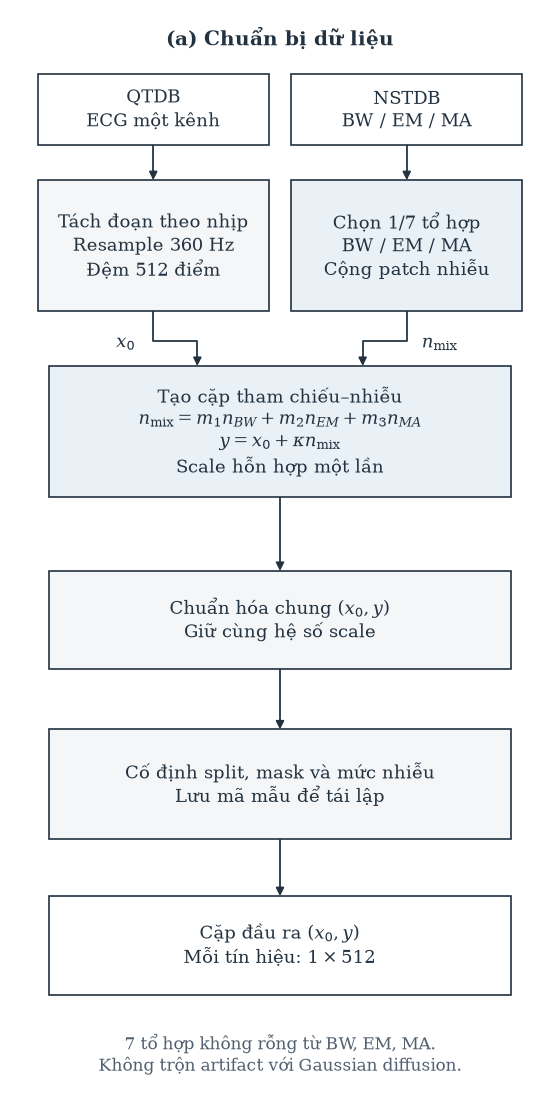

In [18]:
preview_panel('a')

### 9b. Hình (b) — Huấn luyện conditional diffusion

Kiểm tra diffusion thuận, điều kiện đầu vào, mạng dự đoán và các nhánh loss. Chạy lại riêng cell này sau khi sửa `draw_panel_b`.

Kiểm tra nhãn: chữ nằm trong các khối.


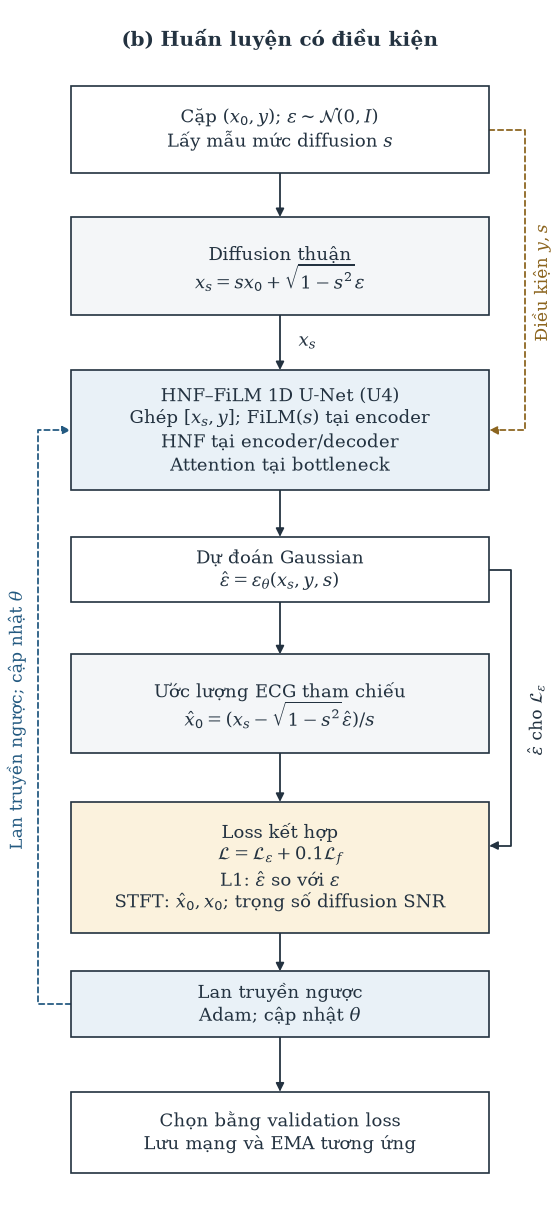

In [19]:
preview_panel('b')

### 9c. Hình (c) — Suy luận DDIM

Kiểm tra đầu vào ECG nhiễu, khởi tạo Gaussian, vòng lặp DDIM và ECG phục hồi. Chạy lại riêng cell này sau khi sửa `draw_panel_c`.

Kiểm tra nhãn: chữ nằm trong các khối.


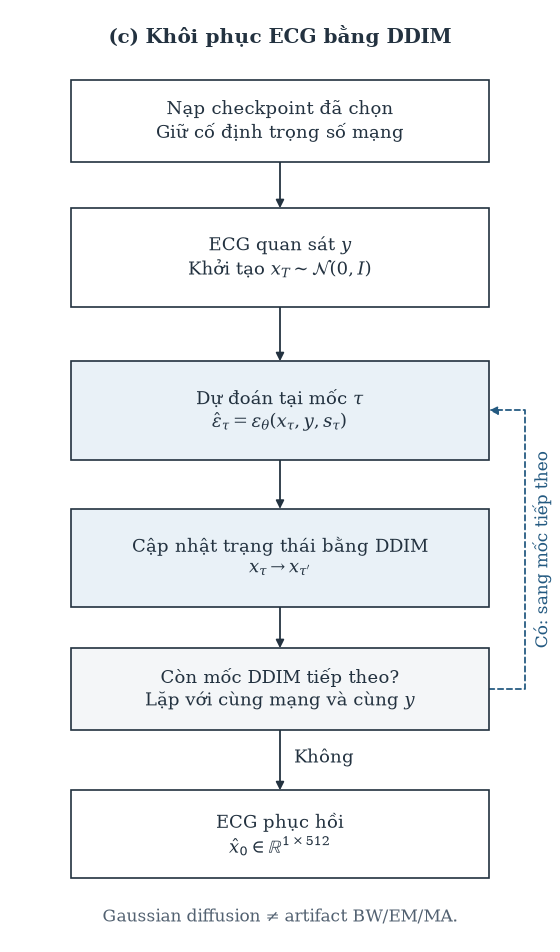

In [20]:
preview_panel('c')

### 9d. Bản tổng quan ba hình dọc — tùy chọn, mặc định tắt

Sau khi kiểm tra ba hình riêng, đặt `SHOW_COMBINED_PREVIEW=True` ở mục 4, chạy lại cell cấu hình rồi cell dưới đây. Bản tổng quan đặt ba panel dọc cạnh nhau ở khổ rộng **10.5 inch**, không thu nhỏ chữ. Khi chèn vào paper, ưu tiên ba PDF riêng thay vì ép bản rộng này vào một cột.

In [21]:
if SHOW_COMBINED_PREVIEW:
    combined_fig = make_system_figure()
    try:
        check_text_fit(combined_fig)
        show_inline(combined_fig)
    finally:
        plt.close(combined_fig)
else:
    print('Đang kiểm tra riêng a/b/c; hình ghép đã tắt.')


Đang kiểm tra riêng a/b/c; hình ghép đã tắt.


## 10. Xuất file và tải xuống — tùy chọn

Mặc định cell này **không làm gì ngoài thông báo** khi Run all. Khi đã chỉnh xong, đặt `EXPORT_FILES=True` rồi chạy riêng cell này để tạo PDF/SVG/PNG **riêng cho từng hình dọc** và ZIP trong thư mục Files của Colab. Chỉ đặt thêm `DOWNLOAD_ZIP=True` nếu muốn tải về máy. Bước xuất tự vẽ lại từ các hàm hiện hành. `EXPORT_COMBINED=True` xuất thêm bản tổng quan `fig01_system.*` nếu cần, mặc định không xuất bản rộng này. PDF/SVG là vector; ưu tiên dùng từng PDF với `width=\columnwidth` trong paper.

In [22]:
EXPORT_FILES = False   # Chỉ đổi True khi đã xem/chỉnh xong hình
DOWNLOAD_ZIP = False   # Chỉ đổi True khi thực sự muốn tải về máy

def export_figure(fig, basename):
    saved = []
    for extension in ('pdf', 'svg', 'png'):
        path = OUTPUT_DIR / f'{basename}.{extension}'
        options = {}
        if extension == 'pdf':
            options['metadata'] = {'Title': basename, 'CreationDate': None, 'ModDate': None}
        elif extension == 'svg':
            options['metadata'] = {'Date': None}
        else:
            options['dpi'] = PNG_DPI
        fig.savefig(path, **options)
        saved.append(path)
    return saved

def export_bundle():
    if not EXPORT_PANELS and not EXPORT_COMBINED:
        raise ValueError('Bật EXPORT_PANELS hoặc EXPORT_COMBINED trước khi xuất.')
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    export_paths, text_warnings = [], {}
    if EXPORT_PANELS:
        for name, basename in PANEL_BASENAMES.items():
            fig, ax = make_panel_figure(name)
            try:
                text_warnings[name] = check_text_fit(fig)
                export_paths.extend(export_figure(fig, basename))
            finally:
                plt.close(fig)
    if EXPORT_COMBINED:
        fig = make_system_figure()
        try:
            text_warnings['combined'] = check_text_fit(fig)
            export_paths.extend(export_figure(fig, 'fig01_system'))
        finally:
            plt.close(fig)
    specification = {
    'figure': 'fig01_system',
    'kind': 'method_diagram_not_experimental_result',
    'panels': {
        'a': 'QTDB + NSTDB; 7 noise subsets; paired data preparation',
        'b': 'conditional diffusion training; noise prediction; weighted spectral objective',
        'c': 'conditional DDIM inference from Gaussian initialization',
    },
    'ecg_channels': 1,
    'tensor_length': 512,
    'resample_hz': 360,
    'lambda_frequency': 0.1,
    'layout': 'portrait_panels_top_to_bottom',
    'panel_width_inches': PANEL_WIDTH_IN,
    'panel_heights_inches': PANEL_HEIGHTS_IN,
    'export_combined': EXPORT_COMBINED,
    'png_dpi': PNG_DPI,
    'font_scale': FONT_SCALE,
    'grayscale': GRAYSCALE,
    'text_fit_warnings': text_warnings,
    }
    spec_path = OUTPUT_DIR / 'figure_specification.json'
    spec_path.write_text(json.dumps(specification, ensure_ascii=False, indent=2), encoding='utf-8')
    export_paths.append(spec_path)
    zip_path = OUTPUT_DIR / 'fig01_system_colab.zip'
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for path in export_paths:
            archive.write(path, arcname=path.name)
    for path in export_paths:
        print(path.name, f'({path.stat().st_size:,} bytes)')
    print('ZIP:', zip_path)
    return zip_path

if EXPORT_FILES:
    zip_path = export_bundle()
    if DOWNLOAD_ZIP:
        try:
            from google.colab import files
        except ImportError:
            print('Ngoài Colab: mở ZIP tại đường dẫn phía trên.')
        else:
            files.download(str(zip_path))
else:
    print('Đang chỉ xem hình trong notebook; chưa xuất hoặc tải file.')
    print('Khi cần: đặt EXPORT_FILES=True; DOWNLOAD_ZIP=True chỉ nếu muốn tải.')


Đang chỉ xem hình trong notebook; chưa xuất hoặc tải file.
Khi cần: đặt EXPORT_FILES=True; DOWNLOAD_ZIP=True chỉ nếu muốn tải.


## 11. Chú thích hình gợi ý cho bài báo

**Hình 1.** Luồng hoạt động của hệ thống khử nhiễu ECG: (a) tạo cặp ECG tham chiếu–nhiễu từ QTDB và bảy tổ hợp BW/EM/MA của NSTDB; (b) huấn luyện mạng dự đoán Gaussian với loss thời gian–tần số; (c) phục hồi ECG qua các bước DDIM có điều kiện. Gaussian trong quá trình diffusion khác với artifact cộng vào ECG quan sát. Các tín hiệu trong nhánh mô hình được biểu diễn ở miền đã chuẩn hóa.

```latex
% Chèn từng sơ đồ dọc vào một cột, không nén cả ba sơ đồ vào một cột.
\begin{figure}[t]
  \centering
  \includegraphics[width=\columnwidth]{fig01a_data_preparation.pdf}
  \caption{Chuẩn bị cặp dữ liệu ECG tham chiếu–nhiễu.}
  \label{fig:data-preparation}
\end{figure}
% Tương tự: fig01b_training.pdf và fig01c_inference.pdf.
```

Khi chỉnh sửa, kiểm tra chữ/đường nối ở kích thước in thực tế. Nếu cảnh báo nhãn xuất hiện, tăng chiều rộng/chiều cao hoặc ngắt dòng nội dung; không cần tải lại dữ liệu hay huấn luyện mô hình để vẽ sơ đồ này.
